----2026/11/11-----

本 notebook 基于 Roboflow 的示例笔记本改编，使用 YOLOv8s-seg 预训练模型进行自定义数据集的实例分割训练。主要包括数据集加载与配置、模型训练、验证集预测、结果可视化，以及训练结果的打包下载

[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLOv8 Object Detection on a Custom Dataset

---

[![Roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset)
[![YouTube](https://badges.aleen42.com/src/youtube.svg)](https://youtu.be/wuZtUMEiKWY)
[![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

Ultralytics YOLOv8 is a popular version of the YOLO (You Only Look Once) object detection and image segmentation model developed by Ultralytics. The YOLOv8 model is designed to be fast, accurate, and easy to use, making it an excellent choice for a wide range of object detection and image segmentation tasks. It can be trained on large datasets and is capable of running on a variety of hardware platforms, from CPUs to GPUs.

## Disclaimer

If you notice that our notebook behaves incorrectly - especially if you experience errors that prevent you from going through the tutorial - don't hesitate! Let us know and open an [issue](https://github.com/roboflow/notebooks/issues) on the Roboflow Notebooks repository.

## Accompanying Blog Post

We recommend that you follow along in this notebook while reading the accompanying [Blog Post](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset/).

## Pro Tip: Use GPU Acceleration

If you are running this notebook in Google Colab, navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`. This will ensure your notebook uses a GPU, which will significantly speed up model training times.

## Steps in this Tutorial

In this tutorial, we are going to cover:

- Before you start
- Install YOLOv8
- CLI Basics
- Inference with Pre-trained COCO Model
- Roboflow Universe
- Preparing a custom dataset
- Custom Training
- Validate Custom Model
- Inference with Custom Model

**Let's begin!**

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
print('new run start')

new run start


In [2]:
!nvidia-smi

Fri Nov 13 07:51:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [4]:
!pip install -q ultralytics
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
from ultralytics import YOLO

True
Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
from IPython.display import display, Image
model = YOLO("yolov8s-seg.pt")

### 加载人工标注数据集

从 Google Drive 下载并解压人工标注后的 YOLO 数据集。数据集目录结构如下：

```text
YOLO_dataset/
├── images/
│   ├── train/
│   └── val/
└── labels/
    ├── train/
    └── val/
```

其中，`images` 存放训练和验证图像，`labels` 存放对应的 YOLO 格式标注文件。

In [6]:
from google.colab import drive
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/YOLO_dataset_metal.zip" /content/
!unzip -q /content/YOLO_dataset_metal.zip -d /content/
!ls -lh /content/YOLO_dataset_metal.zip
!file /content/YOLO_dataset_metal.zip

Mounted at /content/drive
-rw------- 1 root root 22M Nov 13 07:53 /content/YOLO_dataset_metal.zip
/content/YOLO_dataset_metal.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [7]:
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/YOLO_dataset_new.zip" /content/
!unzip -q /content/YOLO_dataset_new.zip -d /content/
!ls -lh /content/YOLO_dataset_new.zip
!file /content/YOLO_dataset_new.zip


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-rw------- 1 root root 66M Nov 13 07:53 /content/YOLO_dataset_new.zip
/content/YOLO_dataset_new.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [8]:
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/YOLO_dataset_aug.zip" /content/
!unzip -q /content/YOLO_dataset_aug.zip -d /content/
!ls -lh /content/YOLO_dataset_aug.zip
!file /content/YOLO_dataset_aug.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-rw------- 1 root root 478M Nov 13 07:54 /content/YOLO_dataset_aug.zip
/content/YOLO_dataset_aug.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [9]:
import os
import shutil

folder1 = "YOLO_dataset_metal"
folder2 = "YOLO_dataset_new"
output_folder = "YOLO_dataset_combined"

os.makedirs(output_folder, exist_ok=True)

# copy folder1
shutil.copytree(
    folder1,
    output_folder,
    dirs_exist_ok=True
)

# copy folder2
shutil.copytree(
    folder2,
    output_folder,
    dirs_exist_ok=True
)

print("Combined!")

Combined!


### 训练集数据增强

在模型训练前，对 `images/train` 中的原始灰度图像分别进行高斯噪声添加、CLAHE（对比度受限自适应直方图均衡化）和对比度调整，每张原始图像生成三个增强版本。

增强图像保存至原 `images/train` 文件夹，文件名分别添加 `_noise`、`_clahe` 和 `_contrast` 后缀，原始图像保留。

上述操作不改变图像尺寸和目标位置，因此无需修改分割标注，只需将对应的 YOLO `.txt` 标注文件复制至 `labels/train`，并使用与增强图像一致的文件名主干。

仅对训练集进行增强，验证集保持不变。重复运行时，跳过本段代码已生成的增强图像和标注，避免重复增强。

In [10]:
from pathlib import Path
import cv2
import numpy as np
import shutil
from skimage.util import random_noise
# Data Augmentation
# ============================================================
# 1. Paths
# ============================================================

src_dir = Path("/content/YOLO_dataset_combined")
dst_dir = Path("/content/YOLO_dataset_combined_aug")

src_img_dir = src_dir / "images/train"
src_label_dir = src_dir / "labels/train"

dst_img_dir = dst_dir / "images/train"
dst_label_dir = dst_dir / "labels/train"

for split in ["train", "val"]:
    (dst_dir / "images" / split).mkdir(parents=True, exist_ok=True)
    (dst_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

np.random.seed(42)
rng = np.random.default_rng(42)


# ============================================================
# 2. Augmentation functions
# ============================================================

def add_noise(img):
    sigma = rng.uniform(2, 8)
    noisy = random_noise(img, mode="gaussian", var=(sigma / 255)**2, rng=rng)
    return (noisy * 255).astype(np.uint8)


def add_clahe(img):
    clahe = cv2.createCLAHE(
        clipLimit=rng.uniform(1.5, 3.0),
        tileGridSize=(8, 8)
    )
    return clahe.apply(img)


def adjust_contrast(img):
    alpha = rng.uniform(0.85, 1.4)
    x = img.astype(np.float32) / 255
    mean = x.mean()
    x = (x - mean) * alpha + mean
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)


# ============================================================
# 3. Augment training images
# ============================================================

img_paths = sorted(
    p for p in src_img_dir.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
)

count = 0

for img_path in img_paths:

    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        print("Failed image:", img_path.name)
        continue

    label_path = src_label_dir / f"{img_path.stem}.txt"

    if not label_path.exists():
        print("Missing label:", label_path.name)
        continue

    versions = {
        "original": img,
        "noise": add_noise(img),
        "clahe": add_clahe(img),
        "contrast": adjust_contrast(img)
    }

    for suffix, image in versions.items():
        name = f"{img_path.stem}_{suffix}"
        cv2.imwrite(str(dst_img_dir / f"{name}.png"), image)
        shutil.copy2(label_path, dst_label_dir / f"{name}.txt")

    count += 1

print(f"Augmented {count} training images.")


# ============================================================
# 4. Copy validation images and labels (no augmentation)
# ============================================================

for folder in ["images", "labels"]:
    src = src_dir / folder / "val"
    dst = dst_dir / folder / "val"

    for path in src.iterdir():
        if path.is_file():
            shutil.copy2(path, dst / path.name)


# ============================================================
# 5. Check dataset
# ============================================================

for split in ["train", "val"]:

    img_dir = dst_dir / "images" / split
    label_dir = dst_dir / "labels" / split

    images = {
        p.stem for p in img_dir.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    }
    labels = {p.stem for p in label_dir.glob("*.txt")}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", images - labels)
    print("Labels without images:", labels - images)

print("\nData augmentation completed!")

Augmented 55 training images.

TRAIN
Images: 220
Labels: 220
Images without labels: set()
Labels without images: set()

VAL
Images: 12
Labels: 12
Images without labels: set()
Labels without images: set()

Data augmentation completed!


In [11]:
from pathlib import Path
import shutil

old_dir = Path("/content/YOLO_dataset_aug")
new_dir = Path("/content/YOLO_dataset_combined_aug")
out_dir = Path("/content/YOLO_dataset_v4")

# Create directories
for split in ["train", "val"]:
    for folder in ["images", "labels"]:
        (out_dir / folder / split).mkdir(parents=True, exist_ok=True)

# Merge datasets
for prefix, src_dir in [("old", old_dir), ("new", new_dir)]:
    for split in ["train", "val"]:
        img_dir = src_dir / "images" / split
        label_dir = src_dir / "labels" / split

        for img_path in img_dir.iterdir():
            if img_path.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
                continue

            label_path = label_dir / f"{img_path.stem}.txt"
            if not label_path.exists():
                print("Missing label:", img_path)
                continue

            shutil.copy2(img_path, out_dir / "images" / split / f"{prefix}_{img_path.name}")
            shutil.copy2(label_path, out_dir / "labels" / split / f"{prefix}_{img_path.stem}.txt")

# Check dataset
for split in ["train", "val"]:
    images = list((out_dir / "images" / split).iterdir())
    labels = list((out_dir / "labels" / split).glob("*.txt"))
    print(f"{split}: {len(images)} images, {len(labels)} labels")

train: 516 images, 516 labels
val: 21 images, 21 labels


In [13]:
%%writefile /content/YOLO_dataset_v4/data.yaml
path: /content/YOLO_dataset_v4

train: images/train
val: images/val

names:
  0: patient
  1: metal
  2: fabric

Writing /content/YOLO_dataset_v4/data.yaml


### 训练迭代：基于新增数据微调模型

从 Google Drive 加载上一轮训练保存的模型权重，并导入包含原有数据和新增标注数据的更新版数据集。在已有权重的基础上进行微调，完成后保存本轮模型权重和训练结果。

注意：数据集的类别编号及名称应与上一轮保持一致；新增数据应合理划分至训练集和验证集，避免同一图像及其增强版本跨集合出现。

In [14]:
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/best_v3.pt" /content/


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
# 基于上一轮的最佳模型权重，在更新后的数据集上微调。可根据选择进行数据增强。
weight_path = "/content/drive/MyDrive/best_v3.pt"

model = YOLO(weight_path)
results = model.train(
    data="/content/YOLO_dataset_v4/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    lr0=0.001,
    device=0,
    project="/content/runs/segment",
    name="yolo_v4"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/YOLO_dataset_v4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/best_v3.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_v4-2, nbs=64, nms=None, o

/content


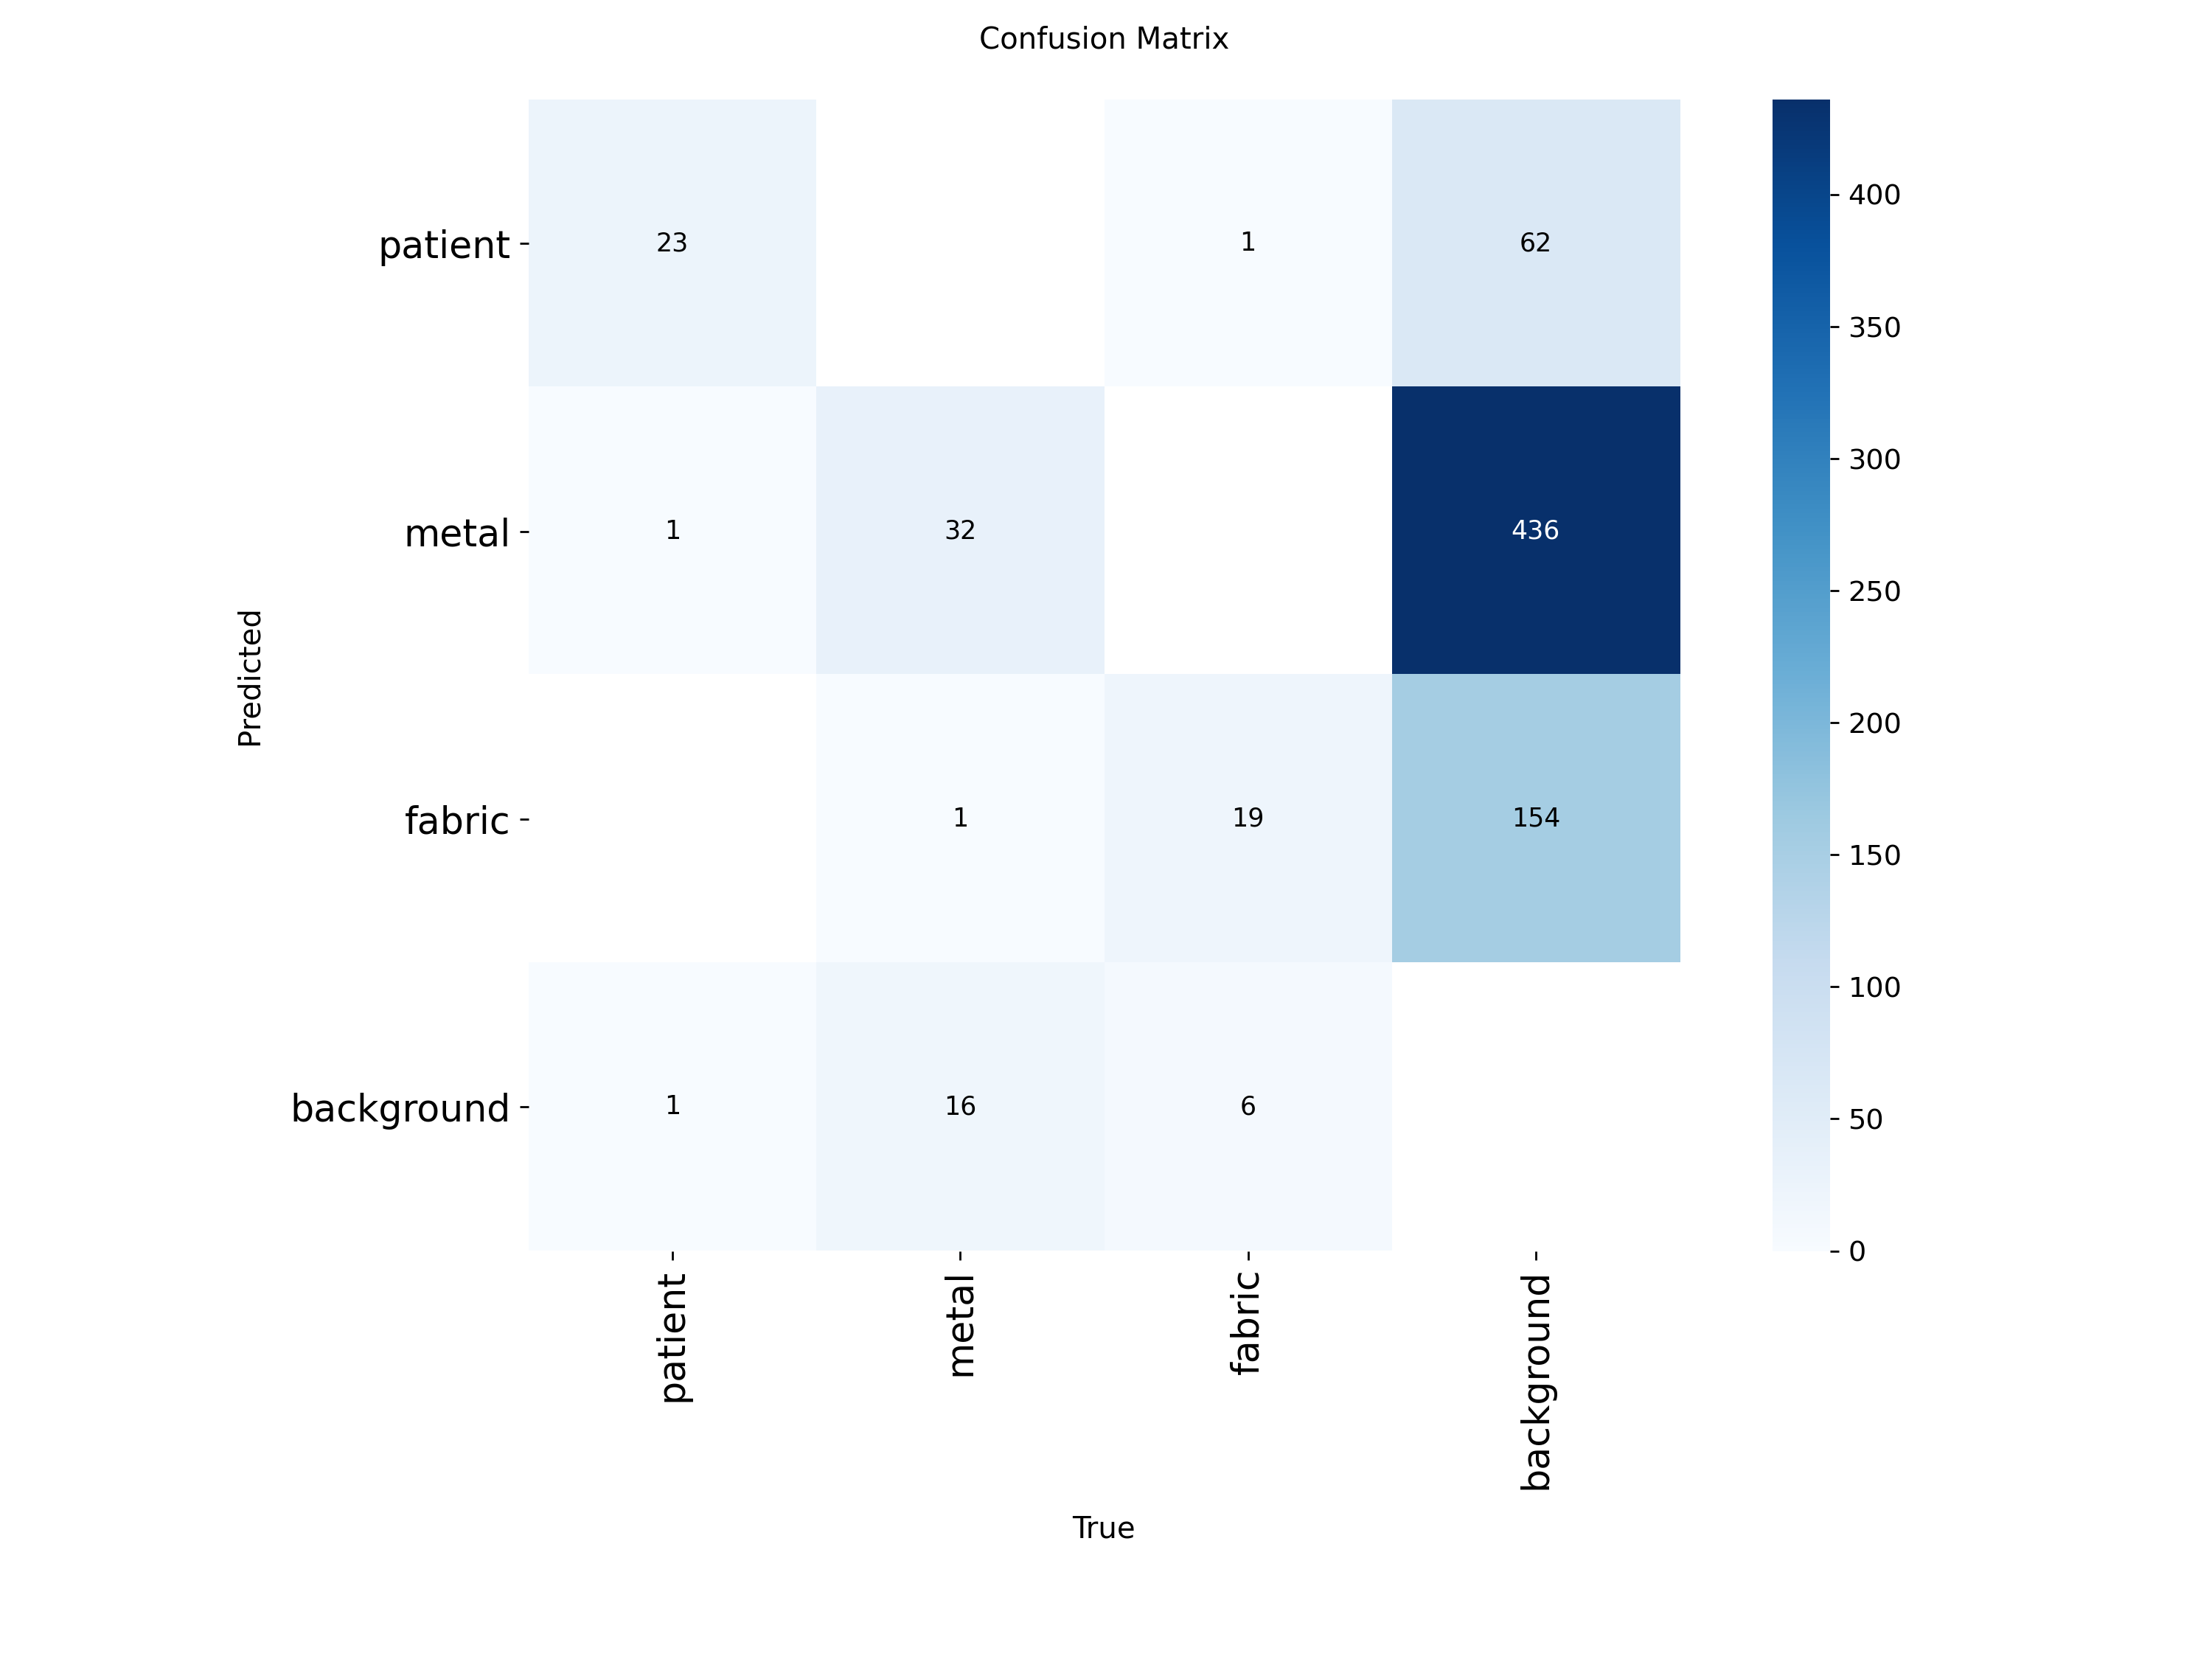

In [27]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

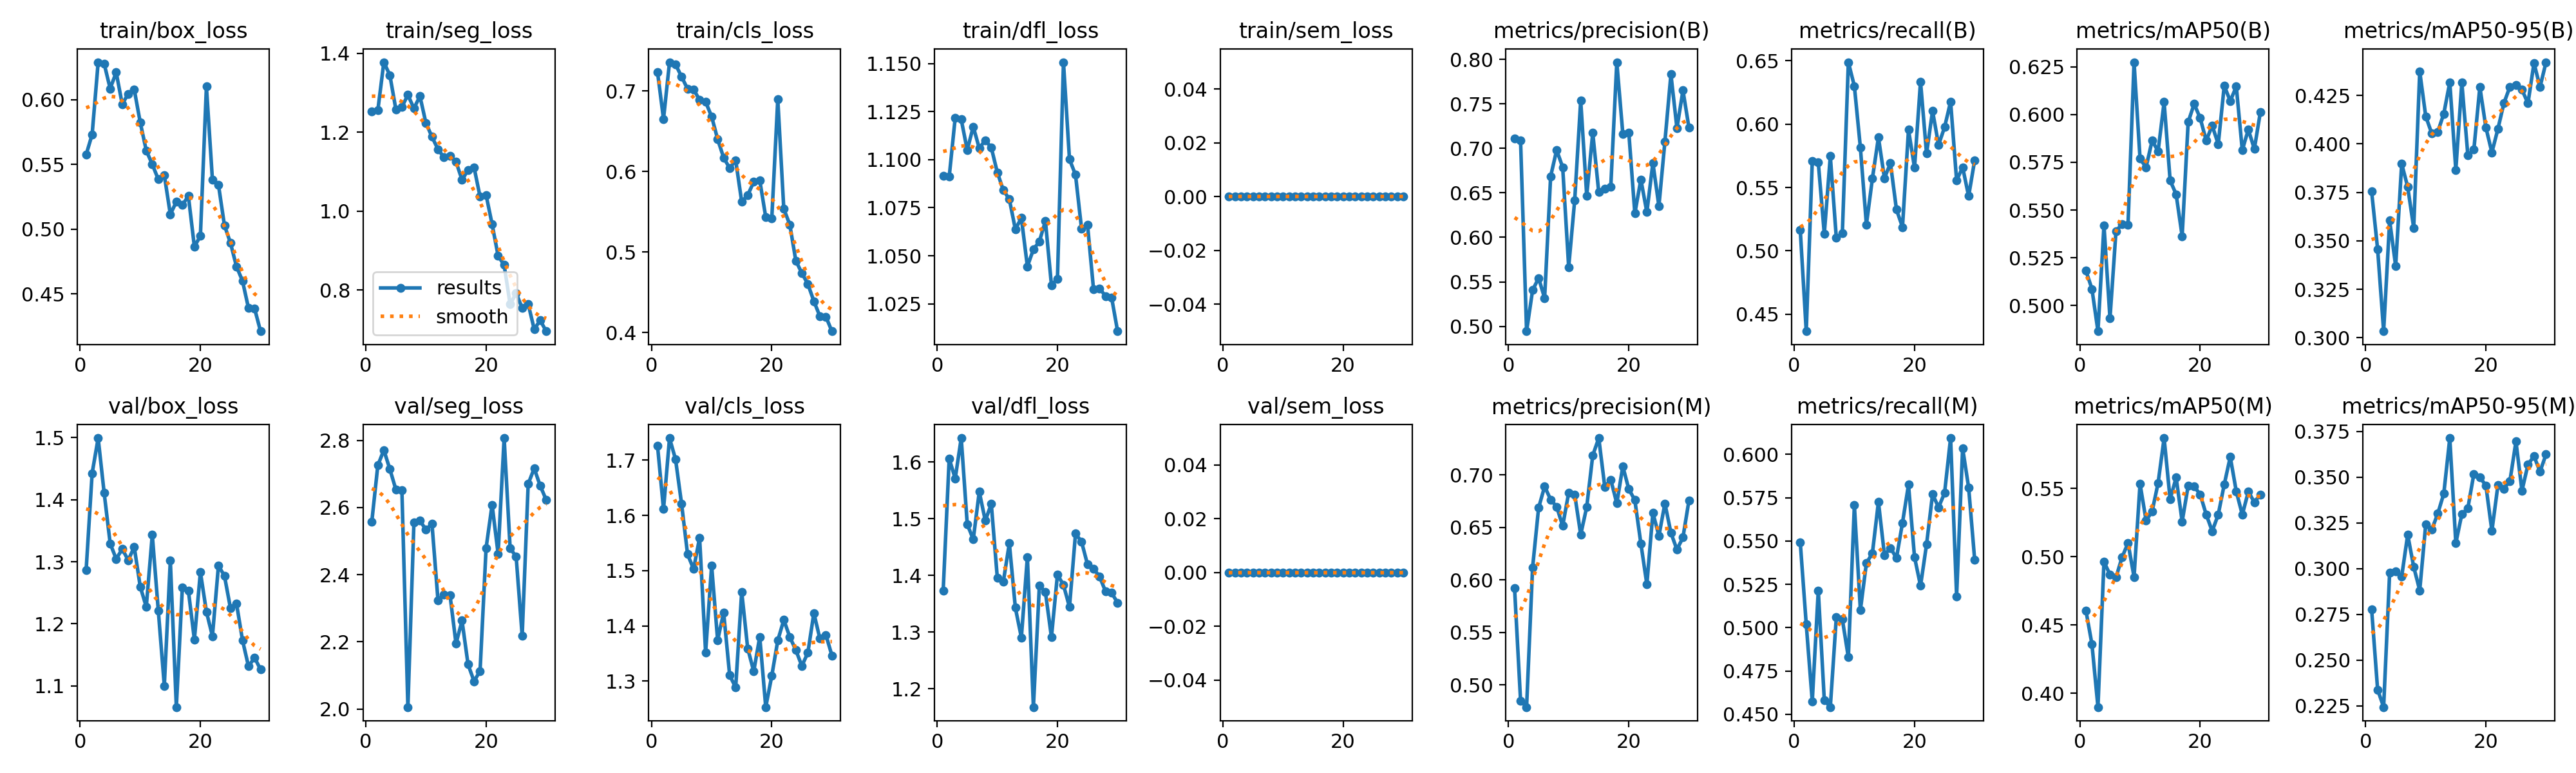

In [28]:
display(Image(filename="/content/runs/segment/train/results.png", width=1200))

In [23]:
model = YOLO("/content/runs/segment/train/weights/best.pt")
pred_results = model.predict(
    source="/content/YOLO_dataset_v4/images/val",
    conf=0.1,
    imgsz=640,
    device=0
)


image 1/21 /content/YOLO_dataset_v4/images/val/new_20260623-182736-ProcessedImagex000008_detResult_uint16_2048x2048.png: 640x640 1 patient, 6 metals, 1 fabric, 20.9ms
image 2/21 /content/YOLO_dataset_v4/images/val/new_20260922-122721-ProcessedImagex000002_detResult_uint16_2048x2048.png: 640x640 1 patient, 5 metals, 2 fabrics, 20.9ms
image 3/21 /content/YOLO_dataset_v4/images/val/new_269.png: 640x640 1 patient, 2 metals, 1 fabric, 21.0ms
image 4/21 /content/YOLO_dataset_v4/images/val/new_277.png: 640x640 1 patient, 6 metals, 19.3ms
image 5/21 /content/YOLO_dataset_v4/images/val/new_309.png: 640x640 1 patient, 2 metals, 1 fabric, 19.3ms
image 6/21 /content/YOLO_dataset_v4/images/val/new_318.png: 640x640 1 patient, 3 metals, 2 fabrics, 19.3ms
image 7/21 /content/YOLO_dataset_v4/images/val/new_326.png: 640x640 1 patient, 3 fabrics, 19.3ms
image 8/21 /content/YOLO_dataset_v4/images/val/new_330.png: 640x640 1 patient, 2 metals, 2 fabrics, 19.3ms
image 9/21 /content/YOLO_dataset_v4/images/va

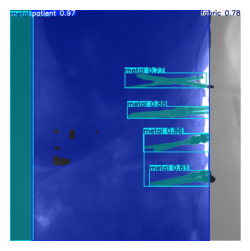

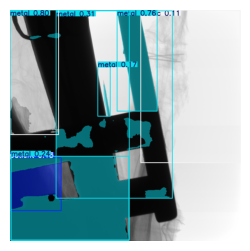

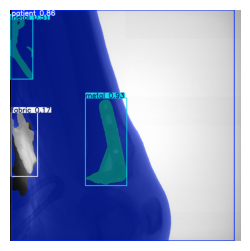

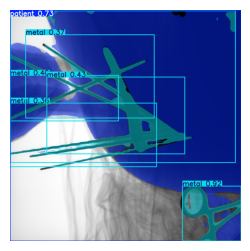

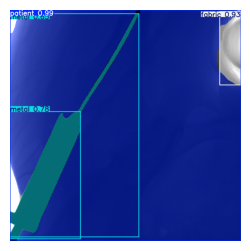

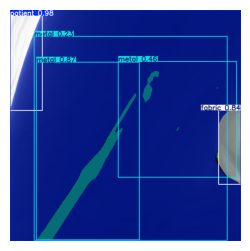

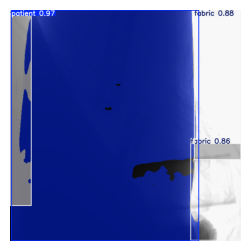

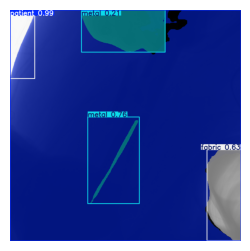

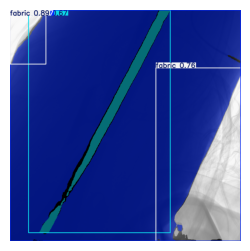

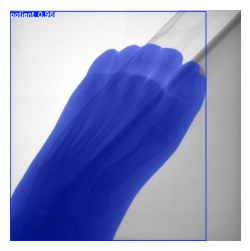

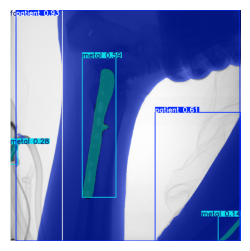

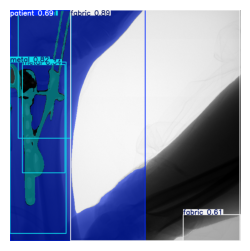

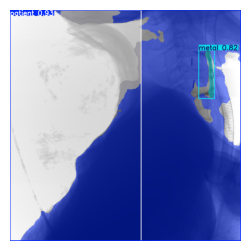

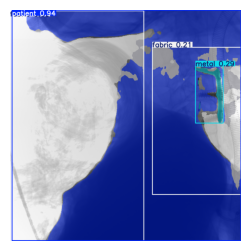

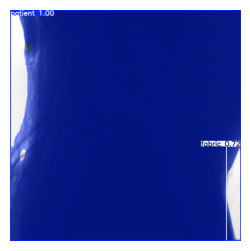

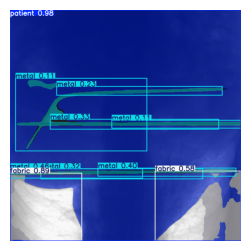

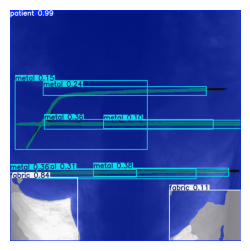

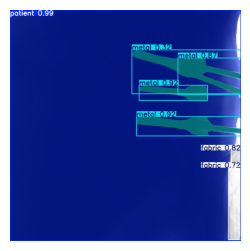

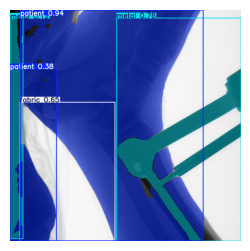

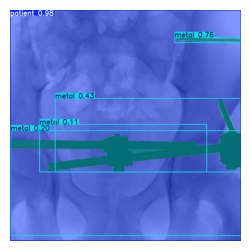

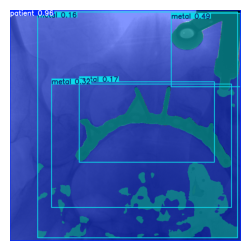

In [24]:
import matplotlib.pyplot as plt

for result in pred_results:
    annotated = result.plot()

    plt.figure(figsize=(3, 3))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    #plt.title(result.path.split("/")[-1])
    plt.show()

In [30]:
from pathlib import Path
import shutil

# 训练得到的 best.pt
run_file = Path("/content/runs/segment/yolo_v4-2/weights/best.pt")

# 保存到 Google Drive，并重命名为 best_v4.pt
save_file = Path("/content/drive/MyDrive/best_v4.pt")

# 确保目标文件夹存在
save_file.parent.mkdir(parents=True, exist_ok=True)

# 复制并重命名
shutil.copy2(run_file, save_file)

print(f"模型已保存到：{save_file}")


模型已保存到：/content/drive/MyDrive/best_v4.pt


## 🏆 Congratulations

### Learning Resources

Roboflow has produced many resources that you may find interesting as you advance your knowledge of computer vision:

- [Roboflow Notebooks](https://github.com/roboflow/notebooks): A repository of over 20 notebooks that walk through how to train custom models with a range of model types, from YOLOv7 to SegFormer.
- [Roboflow YouTube](https://www.youtube.com/c/Roboflow): Our library of videos featuring deep dives into the latest in computer vision, detailed tutorials that accompany our notebooks, and more.
- [Roboflow Discuss](https://discuss.roboflow.com/): Have a question about how to do something on Roboflow? Ask your question on our discussion forum.
- [Roboflow Models](https://roboflow.com): Learn about state-of-the-art models and their performance. Find links and tutorials to guide your learning.

### Convert data formats

Roboflow provides free utilities to convert data between dozens of popular computer vision formats. Check out [Roboflow Formats](https://roboflow.com/formats) to find tutorials on how to convert data between formats in a few clicks.

### Connect computer vision to your project logic

[Roboflow Templates](https://roboflow.com/templates) is a public gallery of code snippets that you can use to connect computer vision to your project logic. Code snippets range from sending emails after inference to measuring object distance between detections.